In [10]:
import os
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torch.nn as nn
import torch.nn.functional as F

import joblib

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch:", torch.__version__)
print("cuda:", torch.version.cuda)
print(f"device: {device}")

torch: 2.7.1+cu118
cuda: 11.8
device: cuda


In [11]:
class SegmentationDataset(Dataset):
    def __init__(self, root_dir, cash=True):
        self.samples = []
        self.cache = [] if cash else None

        classes = {
            "Cucumber": 1,
            "Strawberry": 2
        }
        
        for cls_name, cls_id in classes.items():
            img_dir = os.path.join(root_dir, cls_name, "img")
            mask_dir = os.path.join(root_dir, cls_name, "mask")
            
            for fname in os.listdir(img_dir):
                img_path = os.path.join(img_dir, fname)
                mask_path = os.path.join(mask_dir, fname)
                
                if os.path.exists(mask_path):
                    if cash:
                        img = cv2.imread(img_path)
                        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                        img = cv2.resize(img, (256, 256))

                        mask = cv2.imread(mask_path, 0)
                        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_NEAREST)
                        
                        mask = (mask > 127).astype(np.uint8) * cls_id
                        
                        img = img.astype(np.float32) / 255.0

                        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1,1,3)
                        std  = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1,1,3)
                        img = (img - mean) / std

                        img = np.transpose(img, (2, 0, 1))
                        
                        self.cache.append((img, mask))
                    else:
                        self.samples.append((img_path, mask_path, cls_id))
    
    def __len__(self):
        if self.cache is not None:
            return len(self.cache)
        return len(self.samples)
    
    def __getitem__(self, idx):
        if self.cache is not None:
            img, mask = self.cache[idx]
            return torch.tensor(img), torch.tensor(mask, dtype=torch.long)
    
        # fallback (если без кеша)
        img_path, mask_path, cls_id = self.samples[idx]

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (256, 256))

        mask = cv2.imread(mask_path, 0)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_NEAREST)

        mask = (mask > 127).astype(np.uint8) * cls_id

        img = img.astype(np.float32) / 255.0
        img = np.transpose(img, (2, 0, 1))

        return torch.tensor(img), torch.tensor(mask, dtype=torch.long)
    
full_dataset = SegmentationDataset("./data/data_seg/cpaug")

train_size = int(0.7 * len(full_dataset))
val_size = int(0.2 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_ds, val_ds, test_ds = random_split(
    full_dataset, [train_size, val_size, test_size]
)

train_loader = DataLoader(train_ds, batch_size=12, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=12, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=12, shuffle=False, num_workers=0, pin_memory=True)


In [12]:
imgs, masks = next(iter(train_loader))

print("Mask unique values:", torch.unique(masks))

Mask unique values: tensor([0, 1, 2])


Epoch 1/20 | Train loss: 0.7343; Train IoU: 0.1709 | Val loss: 0.6966; Vall Iou: 0.2241
Epoch 2/20 | Train loss: 0.5339; Train IoU: 0.2207 | Val loss: 0.4050; Vall Iou: 0.2571
Epoch 3/20 | Train loss: 0.4414; Train IoU: 0.2572 | Val loss: 0.4620; Vall Iou: 0.2827
Epoch 4/20 | Train loss: 0.4188; Train IoU: 0.2762 | Val loss: 0.5440; Vall Iou: 0.2494
Epoch 5/20 | Train loss: 0.3937; Train IoU: 0.2853 | Val loss: 0.2952; Vall Iou: 0.3329
Epoch 6/20 | Train loss: 0.3450; Train IoU: 0.3114 | Val loss: 0.2561; Vall Iou: 0.3562
Epoch 7/20 | Train loss: 0.3109; Train IoU: 0.3359 | Val loss: 0.4049; Vall Iou: 0.2880
Epoch 8/20 | Train loss: 0.3197; Train IoU: 0.3348 | Val loss: 0.2395; Vall Iou: 0.3636
Epoch 9/20 | Train loss: 0.3101; Train IoU: 0.3344 | Val loss: 0.2783; Vall Iou: 0.3781
Epoch 10/20 | Train loss: 0.2693; Train IoU: 0.3544 | Val loss: 0.2713; Vall Iou: 0.3555
Epoch 11/20 | Train loss: 0.2568; Train IoU: 0.3693 | Val loss: 0.1822; Vall Iou: 0.3883
Epoch 12/20 | Train loss: 0.22

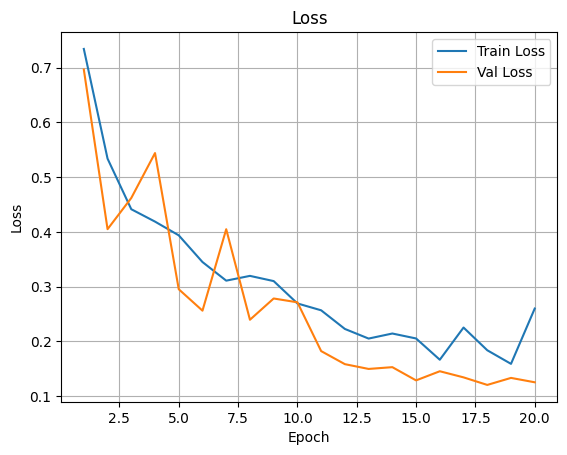

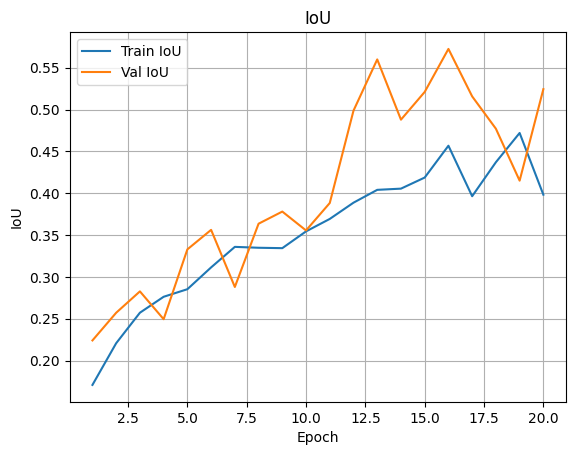

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class BetterUNet(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        
        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.LeakyReLU(0.1),
                
                nn.Conv2d(out_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.LeakyReLU(0.1),
                
                nn.Dropout2d(0.1)
            )
        
        self.enc1 = block(3, 64)
        self.enc2 = block(64, 128)
        self.enc3 = block(128, 256)
        
        self.pool = nn.MaxPool2d(2)
        
        self.bottleneck = block(256, 512)
        
        # upsampling
        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec3 = block(512 + 256, 256)
        
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec2 = block(256 + 128, 128)
        
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec1 = block(128 + 64, 64)
        
        self.final = nn.Conv2d(64, num_classes, 1)
    
    def forward(self, x):
        # encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        
        # bottleneck
        b = self.bottleneck(self.pool(e3))
        
        # decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)
        
        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)
        
        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)
        
        return self.final(d1)
    
def compute_iou(pred, target, num_classes=3):
    pred = torch.argmax(pred, dim=1)
    ious = []

    for cls in range(1, num_classes):
        pred_inds = (pred == cls)
        target_inds = (target == cls)

        intersection = (pred_inds & target_inds).sum().item()
        union = (pred_inds | target_inds).sum().item()

        if union == 0:
            continue
        ious.append(intersection / union)

    if len(ious) == 0:
        return 0.0
    
    return sum(ious) / len(ious)

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    
    total_loss = 0
    total_iou = 0
    
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        
        preds = model(imgs)
        loss = criterion(preds, masks)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        total_iou += compute_iou(preds.detach(), masks)
    
    return total_loss / len(loader), total_iou / len(loader)

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    
    total_loss = 0
    total_iou = 0
    
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
            
            preds = model(imgs)
            loss = criterion(preds, masks)
            
            total_loss += loss.item()
            total_iou += compute_iou(preds, masks)
    
    return total_loss / len(loader), total_iou / len(loader)

class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = None
        self.best_state = None
        self.counter = 0

    def step(self, score, model):
        if self.best_score is None:
            self.best_score = score
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            return False

        if score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            self.counter = 0
            return False

        self.counter += 1
        return self.counter >= self.patience

    def restore_best(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)

def fit(model, train_loader, val_loader, optimizer, criterion, device, epochs=10, early_stopping=None):
    
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_iou": [],
        "val_iou": []
    }
    
    for epoch in range(epochs):
        train_loss, train_iou = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )
        
        val_loss, val_iou = evaluate(
            model, val_loader, criterion, device
        )
        
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_iou"].append(train_iou)
        history["val_iou"].append(val_iou)
        
        print(f"Epoch {epoch+1}/{epochs} | Train loss: {train_loss:.4f}; Train IoU: {train_iou:.4f} | Val loss: {val_loss:.4f}; Vall Iou: {val_iou:.4f}")
    
        if early_stopping is not None:
                if early_stopping.step(val_iou, model):
                    print(f"Остановка на эпохе {epoch};\nСворачиваем всю порнографиб, лучший результат: val_acc={early_stopping.best_score}")
                    early_stopping.restore_best(model)
                    break

    return history

def plot_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)
    
    plt.figure()
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Val Loss")
    plt.legend()
    plt.grid(True)
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.show()
    
    plt.figure()
    plt.plot(epochs, history["train_iou"], label="Train IoU")
    plt.plot(epochs, history["val_iou"], label="Val IoU")
    plt.legend()
    plt.grid(True)
    plt.title("IoU")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.show()

model = BetterUNet(num_classes=3).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

def dice_loss(pred, target, eps=1e-6):
    pred = torch.softmax(pred, dim=1)
    
    target = target.unsqueeze(1)
    
    intersection = (pred.gather(1, target) ).sum()
    union = pred.sum() + target.numel()
    
    return 1 - (2 * intersection + eps) / (union + eps)

class_weights = torch.tensor([0.0000000001, 1.0, 1.0]).to(device)
ce = nn.CrossEntropyLoss(weight=class_weights)
def criterion(pred, target):
    return ce(pred, target) + dice_loss(pred, target)

history = fit(model, train_loader, val_loader, optimizer, criterion, device, epochs=20, early_stopping=EarlyStopping(5))
plot_history(history) 

In [15]:
test_loss, test_iou = evaluate(model, test_loader, criterion, device)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test IoU: {test_iou:.4f}")

Test Loss: 0.1275
Test IoU: 0.5120


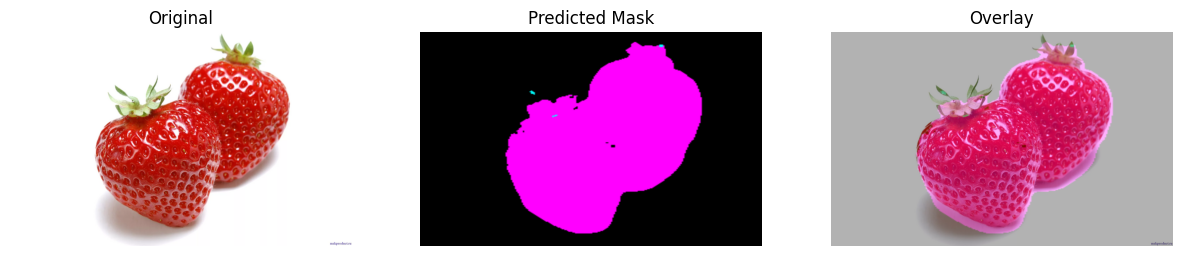

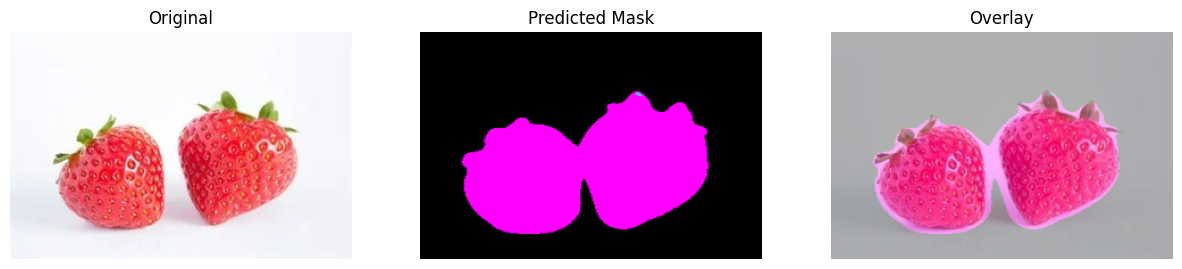

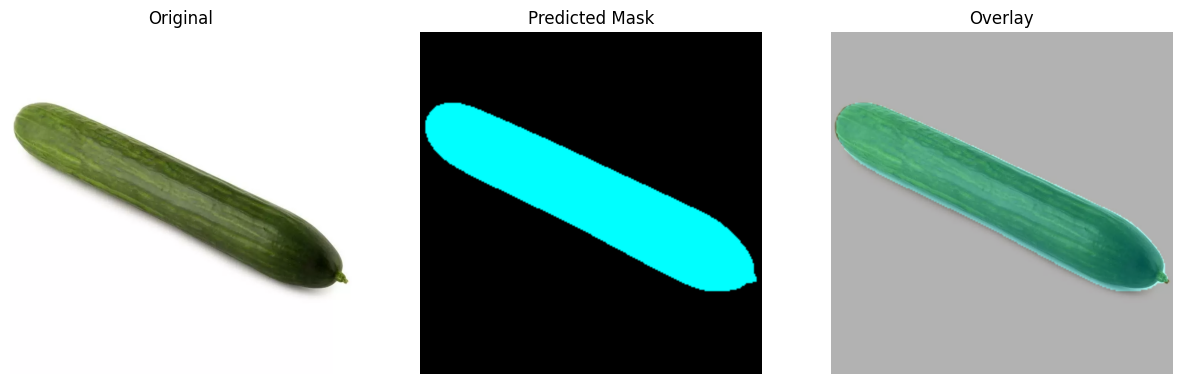

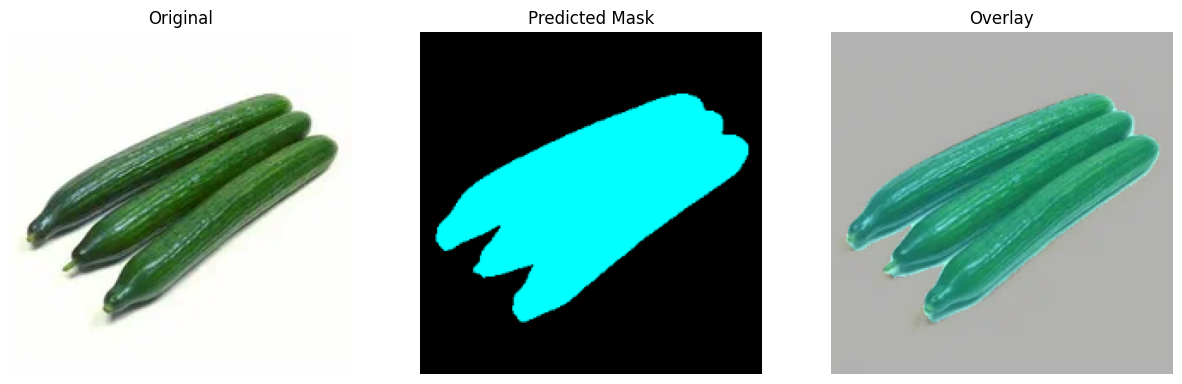

In [45]:
def predict_image(model, image_path, device):
    model.eval()
    
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    img_resized = cv2.resize(img_rgb, (256, 256))
    
    img = img_resized.astype(np.float32) / 255.0
    
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1,1,3)
    std  = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1,1,3)
    
    img = (img - mean) / std
    
    img_tensor = torch.tensor(img).permute(2, 0, 1).unsqueeze(0).to(device)
    
    with torch.no_grad():
        pred = model(img_tensor)
        pred = torch.argmax(pred, dim=1).squeeze().cpu().numpy()
    
    return img_rgb, pred 
    
def decode_mask(mask): 
    color_map = { 0: [0, 0, 0], # фон 
                 1: [0, 255, 255], # огурец — зелёный 
                 2: [255, 0, 255], # клубника — красный 
                 } 
    h, w = mask.shape 
    colored = np.zeros((h, w, 3), dtype=np.uint8) 
    for cls, color in color_map.items(): 
        colored[mask == cls] = color 
    return colored 

def visualize_prediction(model, image_path, device): 
    img, pred_mask = predict_image(model, image_path, device) 
    mask_colored = decode_mask(pred_mask) # ресайз маски обратно к размеру оригинала 
    mask_colored = cv2.resize(mask_colored, (img.shape[1], img.shape[0])) # overlay 
    overlay = cv2.addWeighted(img, 0.7, mask_colored, 0.3, 0) 
    plt.figure(figsize=(15,5)) 
    plt.subplot(1,3,1) 
    plt.title("Original") 
    plt.imshow(img) 
    plt.axis("off") 
    plt.subplot(1,3,2) 
    plt.title("Predicted Mask") 
    plt.imshow(mask_colored) 
    plt.axis("off") 
    plt.subplot(1,3,3) 
    plt.title("Overlay") 
    plt.imshow(overlay) 
    plt.axis("off") 
    plt.show()

visualize_prediction(model, "0.jpg", device)
visualize_prediction(model, "4.jpg", device)
visualize_prediction(model, "1c.jpg", device)
visualize_prediction(model, "2c.jpg", device)











In [29]:
torch.save(model.state_dict(), "bestSegmentatorInTheWorld1.pt")

In [30]:
joblib.dump(model, "bestSegmentatorInTheWorld1.joblib")

['bestSegmentatorInTheWorld1.joblib']